# 05 Baseline forecasts

**What this notebook does.** It builds five simple baseline forecasts, evaluates them on the validation and test blocks and repeats the evaluation on all 54 stores to check how far the development-subset results carry over. No model is trained: a baseline only copies or averages past sales.

## Forecast protocol

The task is a rolling 16-day-ahead forecast: for each target day t the forecast origin is t-16, and only data observed up to the origin are used. Validation targets (15-30 July 2017) have origins from 29 June to 14 July, and test targets (31 July-15 August 2017) have origins from 15 to 30 July. Validation actuals can serve as history for test targets because they were observed before the corresponding test origins.

## Baselines

| Name | Forecast for target day t |
|---|---|
| `naive_lag16` | sales on day t-16 |
| `seasonal_naive_lag21` | sales on day t-21 (same weekday, the latest week available at the origin) |
| `seasonal_naive_lag28` | sales on day t-28 (same weekday, four weeks earlier) |
| `moving_avg_7` | mean of days t-22 to t-16 |
| `moving_avg_28` | mean of days t-43 to t-16 |

Lags of 7 and 14 days are not used because those days fall after the origin. These forecasts are the same as the columns `lag_16`, `lag_21`, `lag_28`, `roll_mean_7` and `roll_mean_28` of notebook 03.

## Evaluation

- **Target:** `unit_sales` clipped at zero. No-record days are missing in the history; the validation and test blocks contain none.
- **Population:** series that have all five forecasts and the actual sales on all 32 target days. Series without history (cold start) are excluded and their share is reported.
- **Metrics:** RMSSE is the main metric because it is scale-independent and can be compared across levels (the scale is the mean squared one-day change in the train period; series with fewer than 30 changes or a zero scale are left out). WAPE is the sum of absolute errors divided by the sum of actual sales. Bias is the sum of forecast minus actual divided by the sum of actual sales.
- **Levels:** store-item, family, store, state and total. For the aggregated levels, forecasts and actual sales of the covered series are summed per day (items and kilograms are added together), the RMSSE of each group uses its own scale, and the groups are averaged.
- **Selection:** the best baseline per level is chosen on validation and read on test.

## 1. Settings

**Purpose.** Read the split dates, horizon and subset from the files written by notebook 03, so that this notebook cannot drift away from the features.

**Method.** `subset_definition.json` gives the stores, items, horizon and cut dates; `feature_spec.json` gives the training filter. The five baselines are defined by a type (lag or moving average) and a number of days.

**Output.** The constants used below and a one-line summary of the split.

In [1]:
import json
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
DIM = BASE / "clean" / "dim"
FIG = BASE / "figures"
RES = BASE / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

defn = json.load(open(BASE / "features" / "subset_definition.json"))
spec = json.load(open(BASE / "features" / "feature_spec.json"))
H = int(defn["horizon_days"])                       # forecast horizon: 16 days
VAL_START = pd.Timestamp(defn["val_start"])
TEST_START = pd.Timestamp(defn["test_start"])
TRAIN_END = VAL_START - pd.Timedelta(days=1)
STORE_LIST = [int(s) for s in defn["stores"]]
ITEM_LIST = [int(i) for i in defn["items"]]

# every baseline uses only values at least 16 days old (known at the forecast origin t-16)
MODELS = {
    "naive_lag16": ("lag", 16),             # value 16 days before the target day
    "seasonal_naive_lag21": ("lag", 21),    # same weekday, most recent week available at the origin
    "seasonal_naive_lag28": ("lag", 28),    # same weekday, four weeks earlier
    "moving_avg_7": ("mean", 7),            # mean of the 7 days ending at the origin
    "moving_avg_28": ("mean", 28),          # mean of the 28 days ending at the origin
}
MIN_DIFFS = 30        # a series needs this many one-day differences in train to have a scale

print(f"horizon {H} days | train ends {TRAIN_END.date()} | validation {VAL_START.date()} to "
      f"{(TEST_START - pd.Timedelta(days=1)).date()} | test starts {TEST_START.date()}")
print("training filter in the feature spec:", spec["training_filter"])

horizon 16 days | train ends 2017-07-14 | validation 2017-07-15 to 2017-07-30 | test starts 2017-07-31
training filter in the feature spec: split == 'train' and is_closed == False


## 2. Baseline engine

**Purpose.** One function that computes the baselines and their errors for any set of stores, so that the development subset and all 54 stores go through exactly the same code.

**Method.** For each store the sales grid is arranged as a day × series matrix on the true calendar; no-record days are set to missing. For every target day t of the validation and test blocks the five forecasts are read from days t-16 and earlier. The scale of each series is the mean squared one-day change in the train period. Series errors are kept per series; forecasts and actual sales of the covered series are also summed into store, state, family and total series, whose errors and scales are computed the same way. A series is flagged as active when it had a sale in the 90 days before the origin of its block.

**Output.** A dictionary with a table per series, a table per aggregated group and coverage counts.

**Limitation.** Aggregated sums add items and kilograms. Series with fewer than 30 one-day changes or a zero scale have no RMSSE; they are still counted in WAPE and bias.

In [2]:

def run_engine(store_list, item_filter=None, keep_rows=False):
    """Rolling 16-day-ahead baselines, computed store by store from the clean sales grid."""
    cal = pd.read_parquet(DIM / "calendar_store.parquet", columns=["date", "store_nbr", "is_closed"])
    stores = pd.read_parquet(DIM / "stores.parquet")
    items = pd.read_parquet(DIM / "items.parquet")
    state_of = dict(zip(stores["store_nbr"].astype(int), stores["state"].astype(str)))
    fam_of = dict(zip(items["item_nbr"].astype(int), items["family"].astype(str)))

    all_days = pd.date_range(cal["date"].min(), cal["date"].max())
    n_days = len(all_days)
    t_end = all_days.get_loc(TRAIN_END)
    t_test = all_days.get_loc(TEST_START)
    eval_idx = np.arange(all_days.get_loc(VAL_START), n_days)
    is_val = eval_idx < t_test
    eval_dates = all_days[eval_idx]
    M, E = len(MODELS), len(eval_idx)

    closed = cal[cal["is_closed"]]
    closed_days = {int(s): all_days.get_indexer(g["date"]) for s, g in closed.groupby("store_nbr")}
    dataset = ds.dataset(BASE / "clean" / "sales_grid", format="parquet", partitioning="hive")

    acc, series_parts, row_parts = {}, [], []
    cov = {"series": 0, "covered": 0, "units_all": 0.0, "units_covered": 0.0}

    def add_group(level, key, Ysub, Psub):
        r = acc.setdefault((level, key), {"sum": np.zeros(n_days), "cnt": np.zeros(n_days),
                                          "pred": np.zeros((M, E))})
        r["sum"] += np.nansum(Ysub, axis=1)
        r["cnt"] += np.isfinite(Ysub).sum(axis=1)
        r["pred"] += Psub.sum(axis=2)

    for s in store_list:
        flt = ds.field("store_nbr") == int(s)
        if item_filter is not None:
            flt = flt & ds.field("item_nbr").isin(list(item_filter))
        t = dataset.to_table(columns=["date", "item_nbr", "unit_sales"], filter=flt).to_pandas()
        if t.empty:
            continue

        d_idx = all_days.get_indexer(t["date"])
        codes, uniq = pd.factorize(t["item_nbr"].to_numpy(), sort=True)
        n = len(uniq)
        Y = np.full((n_days, n), np.nan, dtype="float32")
        Y[d_idx, codes] = t["unit_sales"].to_numpy(dtype="float32")
        if int(s) in closed_days:
            Y[closed_days[int(s)], :] = np.nan

        # RMSSE scale: mean squared one-day change in training
        sq = np.diff(Y[:t_end + 1], axis=0) ** 2
        n_valid = np.isfinite(sq).sum(axis=0)
        scale = np.where(n_valid >= MIN_DIFFS, np.nansum(sq, axis=0) / np.maximum(n_valid, 1), np.nan)
        scale[scale == 0] = np.nan

        # Forecast each target day using data available at t-16 or earlier
        P = np.full((M, E, n), np.nan, dtype="float32")
        for j, ti in enumerate(eval_idx):
            for m, (kind, k) in enumerate(MODELS.values()):
                if kind == "lag":
                    P[m, j] = Y[ti - k]
                else:
                    win = Y[ti - H - (k - 1):ti - H + 1]
                    cnt = np.isfinite(win).sum(axis=0)
                    P[m, j] = np.where(cnt >= (k + 1) // 2,
                                       np.nansum(win, axis=0) / np.maximum(cnt, 1), np.nan)

        A = Y[eval_idx]
        ok = np.isfinite(P).all(axis=(0, 1)) & np.isfinite(A).all(axis=0)
        cov["series"] += n
        cov["covered"] += int(ok.sum())
        cov["units_all"] += float(np.nansum(A))
        cov["units_covered"] += float(np.nansum(A[:, ok]))

        # Active test series: 90 days ending at TRAIN_END
        pos = Y > 0
        rec = {"store_nbr": np.full(n, int(s)), "item_nbr": uniq,
               "family": np.array([fam_of.get(int(i), "UNKNOWN") for i in uniq]),
               "scale": scale, "covered": ok,
               "active_val": pos[t_end - 89:t_end + 1].any(axis=0),
               "active_test": pos[t_end - 89:t_end + 1].any(axis=0)}

        with np.errstate(all="ignore"):
            for split, mask in (("val", is_val), ("test", ~is_val)):
                Ay = A[mask]
                rec[f"{split}__sy"] = Ay.sum(axis=0)
                for m, name in enumerate(MODELS):
                    e = P[m][mask] - Ay
                    rec[f"{split}__{name}__rmsse"] = np.sqrt((e ** 2).mean(axis=0) / scale)
                    rec[f"{split}__{name}__sabs"] = np.abs(e).sum(axis=0)
                    rec[f"{split}__{name}__serr"] = e.sum(axis=0)
        series_parts.append(pd.DataFrame(rec))

        okc = np.where(ok)[0]
        if len(okc):
            Yo, Po = Y[:, okc], P[:, :, okc]
            fam_o = rec["family"][okc]
            add_group("store", int(s), Yo, Po)
            add_group("state", state_of[int(s)], Yo, Po)
            add_group("total", "all", Yo, Po)
            for f in np.unique(fam_o):
                sel = fam_o == f
                add_group("family", f, Yo[:, sel], Po[:, :, sel])

        if keep_rows:
            long = pd.DataFrame({"date": np.repeat(eval_dates, n), "store_nbr": int(s),
                                 "item_nbr": np.tile(uniq, E), "y": A.ravel()})
            for m, name in enumerate(MODELS):
                long[name] = P[m].ravel()
            row_parts.append(long)

    # Aggregated hierarchy levels
    agg = []
    with np.errstate(all="ignore"):
        for (level, key), r in acc.items():
            S = np.where(r["cnt"] > 0, r["sum"], np.nan)
            sq = np.diff(S[:t_end + 1]) ** 2
            nv = int(np.isfinite(sq).sum())
            scale = np.nansum(sq) / nv if nv >= MIN_DIFFS else np.nan
            if not scale > 0:
                scale = np.nan
            y = S[eval_idx]
            for split, mask in (("val", is_val), ("test", ~is_val)):
                for m, name in enumerate(MODELS):
                    e = r["pred"][m][mask] - y[mask]
                    agg.append((level, str(key), split, name, float(np.sqrt((e ** 2).mean() / scale)),
                                float(np.abs(e).sum()), float(y[mask].sum()), float(e.sum())))

    out = {"series": pd.concat(series_parts, ignore_index=True),
           "agg": pd.DataFrame(agg, columns=["level", "key", "split", "model", "rmsse", "sabs", "sy", "serr"]),
           "coverage": cov}
    if keep_rows:
        out["rows"] = pd.concat(row_parts, ignore_index=True)
    return out


## 3. Run on the development subset and check the engine

**Purpose.** Compute the baselines for the 10 stores and 607 items of the development subset and prove that the engine does what notebook 03 did.

**Method.** The engine is run on the subset. Check 1 compares each forecast with the matching feature column in `subset_model` (values and missing pattern); the cell stops if they differ. Check 2 applies the training filter stored in `feature_spec.json` to `subset_model`, so that the filter is used and not only read.

**Output.** Coverage (how many series have history for every baseline), the five comparison lines and the number of rows that pass the training filter (it should equal the number of fitting rows in notebook 03, 5,680,001).

**Limitation.** Series whose first sale falls inside the validation or test block have no history; they are excluded and counted as cold start.

In [3]:
res_sub = run_engine(STORE_LIST, ITEM_LIST, keep_rows=True)

cov = res_sub["coverage"]
print(f"series in the subset: {cov['series']:,} | with history for every baseline: {cov['covered']:,} "
      f"({cov['covered'] / cov['series']:.1%}) | cold start: {cov['series'] - cov['covered']:,}")
print(f"share of the actual units on the target days that belong to covered series: "
      f"{cov['units_covered'] / cov['units_all']:.2%}")

# check 1: the engine must reproduce the baseline columns already stored in subset_model (notebook 03)
sm = pd.read_parquet(BASE / "features" / "subset_model.parquet",
                     columns=["store_nbr", "item_nbr", "date", "split", "lag_16", "lag_21", "lag_28",
                              "roll_mean_7", "roll_mean_28"])
sm = sm[sm["split"].isin(["val", "test"])]
chk = res_sub["rows"].merge(sm, on=["store_nbr", "item_nbr", "date"], how="inner")
pairs = {"naive_lag16": "lag_16", "seasonal_naive_lag21": "lag_21", "seasonal_naive_lag28": "lag_28",
         "moving_avg_7": "roll_mean_7", "moving_avg_28": "roll_mean_28"}
for model, col in pairs.items():
    both = chk[model].notna() & chk[col].notna()
    same_values = np.allclose(chk.loc[both, model], chk.loc[both, col], rtol=1e-4, atol=1e-4)
    same_missing = bool((chk[model].isna() == chk[col].isna()).all())
    print(f"{model:22s} matches {col:12s}: values {same_values} | missing pattern {same_missing} | rows {len(chk):,}")
    assert same_values and same_missing, f"{model} differs from {col}"

# check 2: the training filter of the feature spec is applied, not just read
cols = ["split", "is_closed"]
n_fit = len(pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols).query(spec["training_filter"]))
print(f"rows that pass the training filter: {n_fit:,}")

series in the subset: 4,876 | with history for every baseline: 4,821 (98.9%) | cold start: 55
share of the actual units on the target days that belong to covered series: 99.62%
naive_lag16            matches lag_16      : values True | missing pattern True | rows 155,416
seasonal_naive_lag21   matches lag_21      : values True | missing pattern True | rows 155,416
seasonal_naive_lag28   matches lag_28      : values True | missing pattern True | rows 155,416
moving_avg_7           matches roll_mean_7 : values True | missing pattern True | rows 155,416
moving_avg_28          matches roll_mean_28: values True | missing pattern True | rows 155,416
rows that pass the training filter: 5,680,001


**Findings.** The subset has 4,876 series; 4,821 (98.9%) have history for every baseline and carry 99.6% of the actual units on the target days. The other 55 series are cold start: they have too little history for at least one baseline on at least one target day, for example products first sold after the train period. All five baselines reproduce the feature columns of notebook 03 exactly (155,416 validation and test rows, same values and same missing pattern), and 5,680,001 rows pass the training filter, equal to the number of fitting rows in notebook 03.

## 4. Accuracy by level

**Purpose.** Compare the five baselines at the store-item, family, store, state and total levels, which answers the first part of the forecasting research question.

**Method.** For each level and baseline: RMSSE (mean and median over series or groups), WAPE and bias. The best baseline per level is chosen on the validation block and its test RMSSE is reported. Bias is the same at every level because all levels use the same covered series; it is printed once.

**Output.** Tables for validation and test, saved as CSV files in `results/`.

**Limitation.** A single 16-day block per split is a small sample, so differences between close baselines may be noise; rolling cross-validation is planned for the next semester. Aggregated levels add items and kilograms.

In [4]:
LEVELS = ["store_item", "family", "store", "state", "total"]


def level_table(res, split):
    """One row per level and baseline: RMSSE (mean and median over series or groups), WAPE and bias."""
    s = res["series"]
    s = s[s["covered"]]
    rows = []
    for m in MODELS:
        r = s.loc[s["scale"].notna(), f"{split}__{m}__rmsse"]
        sy = s[f"{split}__sy"].sum()
        rows.append(("store_item", m, r.mean(), r.median(), s[f"{split}__{m}__sabs"].sum() / sy,
                     s[f"{split}__{m}__serr"].sum() / sy, len(s)))
    a = res["agg"]
    a = a[a["split"] == split]
    for (level, m), g in a.groupby(["level", "model"]):
        rows.append((level, m, g["rmsse"].mean(), g["rmsse"].median(), g["sabs"].sum() / g["sy"].sum(),
                     g["serr"].sum() / g["sy"].sum(), g["key"].nunique()))
    out = pd.DataFrame(rows, columns=["level", "model", "rmsse_mean", "rmsse_median", "wape", "bias", "n_groups"])
    out["level"] = pd.Categorical(out["level"], LEVELS, ordered=True)
    return out.sort_values(["level", "model"]).reset_index(drop=True)


def pivot(tab, col):
    return tab.pivot(index="level", columns="model", values=col)[list(MODELS)]


tab_val = level_table(res_sub, "val")
tab_test = level_table(res_sub, "test")

pd.set_option("display.width", 200)
print("RMSSE (mean over series or groups), validation:")
print(pivot(tab_val, "rmsse_mean").round(3).to_string())
print("\nRMSSE (mean over series or groups), test:")
print(pivot(tab_test, "rmsse_mean").round(3).to_string())
print("\nWAPE, test:")
print(pivot(tab_test, "wape").round(3).to_string())
print("\noverall bias on test (forecast minus actual, relative to actual; the same at every level):")
print(tab_test.groupby("model")["bias"].first()[list(MODELS)].round(3).to_string())

# the baseline is chosen on validation and then read on test
best = pivot(tab_val, "rmsse_mean").idxmin(axis=1)
pt = pivot(tab_test, "rmsse_mean")
print("\nbest baseline on validation per level, and its test RMSSE:")
print(pd.DataFrame({"best_on_validation": best,
                    "test_rmsse": [pt.loc[lv, best[lv]] for lv in best.index]}).round(3).to_string())

RMSSE (mean over series or groups), validation:
model       naive_lag16  seasonal_naive_lag21  seasonal_naive_lag28  moving_avg_7  moving_avg_28
level                                                                                           
store_item        0.924                 0.903                 0.907         0.716          0.691
family            1.334                 1.038                 1.014         0.956          0.844
store             1.539                 1.144                 1.019         0.967          0.775
state             1.494                 1.088                 0.942         0.882          0.730
total             1.656                 0.911                 0.767         0.988          0.805

RMSSE (mean over series or groups), test:
model       naive_lag16  seasonal_naive_lag21  seasonal_naive_lag28  moving_avg_7  moving_avg_28
level                                                                                           
store_item        0.927             

**Findings.** On the development subset no baseline is best everywhere. At the store-item level the moving averages are best on both blocks (RMSSE 0.69 on validation and 0.68 on test for the 28-day average), the seasonal naive baselines reach about 0.89 to 0.90 and the naive baseline 0.93. WAPE falls from 0.59 for the best baseline at the store-item level to 0.10-0.15 at the aggregated levels because errors cancel when series are summed, while RMSSE does not fall with aggregation because each level is scaled by its own one-day variability, so RMSSE is not a measure of accuracy across levels. On the subset the seasonal naive baseline has a lower WAPE than the naive baseline at every level (total 0.109 against 0.147) but not a lower RMSSE at the store level (1.070 against 1.029); this does not appear on all 54 stores (section 6). All baselines forecast 2.5% to 6.8% more than was sold in the test block. Validation and test differ a lot (naive RMSSE at the store level 1.539 against 1.029), so one 16-day block is a noisy sample.

## 5. Accuracy by demand segment and for active series

**Purpose.** Compare the baselines across demand patterns (research question on forecasting performance) and check how much series that may have been discontinued flatter the results.

**Method.** The store-item RMSSE on the test block is averaged by demand class and by ABC group (both from notebook 04, computed on the train period). It is also computed for active series only, i.e. series with at least one sale in the 90 days before the test origin: a baseline that forecasts zero for a discontinued series is correct but not informative.

**Output.** One table for all series against active series, and one table per segment.

**Limitation.** The segments come from the train period only and describe observed sales; ABC is a quantity proxy.

In [5]:
prof = pd.read_parquet(BASE / "features" / "series_profile.parquet",
                       columns=["store_nbr", "item_nbr", "demand_class", "ABC", "XYZ"])
s = res_sub["series"].merge(prof, on=["store_nbr", "item_nbr"], how="left")
s = s[s["covered"] & s["scale"].notna()]
cols_test = [f"test__{m}__rmsse" for m in MODELS]

print("store-item RMSSE on the test block: all covered series vs series with a sale in the 90 days before the origin")
act = s[s["active_test"]]
print(f"active series: {len(act):,} of {len(s):,} ({len(act) / len(s):.1%})")
print(pd.DataFrame({"all": s[cols_test].mean().values, "active only": act[cols_test].mean().values},
                   index=list(MODELS)).round(3).to_string())

for seg in ("demand_class", "ABC"):
    print(f"\nstore-item RMSSE on the test block by {seg} (mean over series):")
    t = s.groupby(seg)[cols_test].mean()
    t.columns = list(MODELS)
    t.insert(0, "series", s.groupby(seg).size())
    print(t.round(3).to_string())

store-item RMSSE on the test block: all covered series vs series with a sale in the 90 days before the origin
active series: 4,378 of 4,820 (90.8%)
                        all  active only
naive_lag16           0.927        0.995
seasonal_naive_lag21  0.895        0.961
seasonal_naive_lag28  0.889        0.954
moving_avg_7          0.713        0.761
moving_avg_28         0.683        0.727

store-item RMSSE on the test block by demand_class (mean over series):
               series  naive_lag16  seasonal_naive_lag21  seasonal_naive_lag28  moving_avg_7  moving_avg_28
demand_class                                                                                               
erratic           935        1.041                 1.021                 0.984         0.805          0.752
intermittent     1280        0.940                 0.916                 0.914         0.736          0.712
lumpy            1518        0.814                 0.787                 0.799         0.618          

**Findings.** Series without a sale in the 90 days before the origin (475 of 4,820 series, about 10%) flatter the average because their errors are near zero: when only the 4,345 active series are kept, the store-item RMSSE rises from 0.68 to 0.76 for the 28-day average and from 0.93 to 1.03 for the naive baseline. The ranking of the baselines does not change: in every demand class and every ABC group the 28-day average is best (RMSSE 0.60 to 0.75), followed by the 7-day average and the seasonal naive baselines, and the naive baseline is the worst. RMSSE is lowest for lumpy series (0.60 for the 28-day average) and highest for erratic series (0.75), but it is relative to the day-to-day variability of each series, which is largest for lumpy series, so it does not mean that lumpy demand is easier to forecast. The 32 series with short history have a near-zero RMSSE (0.10) for every baseline and carry no information.

### Chart 8: Baseline accuracy by level

**Purpose.** Show at a glance how the five baselines compare at each level of the hierarchy.

**Method.** RMSSE on the test block, development subset. A value of 1 (dashed line) means that the error equals the typical one-day change of the series; lower is better.

**Output.** `figures/fig8_baseline_rmsse.png`.

**Limitation.** One 16-day test block per level; the aggregated levels have few groups (1 total, 3 states, 10 stores).

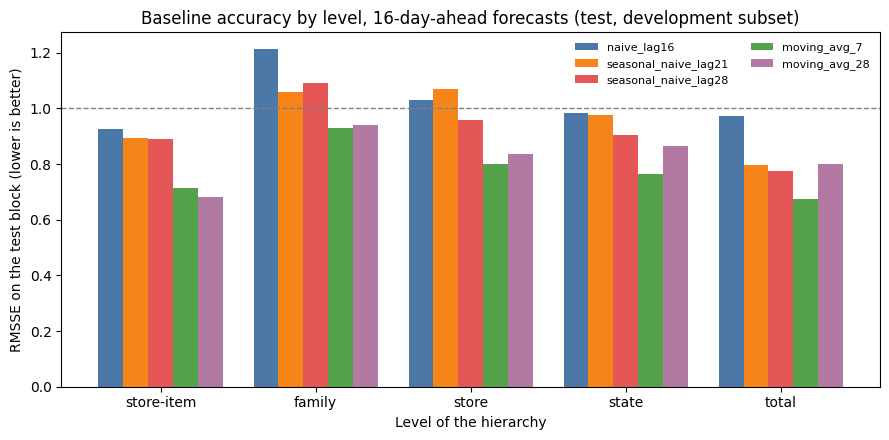

In [6]:
pt = pivot(tab_test, "rmsse_mean")
x = np.arange(len(pt))
width = 0.16
colors = ["#4C78A8", "#F58518", "#E45756", "#54A24B", "#B279A2"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (m, c) in enumerate(zip(MODELS, colors)):
    ax.bar(x + (k - 2) * width, pt[m], width=width, label=m, color=c)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xticks(x, [str(i).replace("_", "-") for i in pt.index])
ax.set_xlabel("Level of the hierarchy")
ax.set_ylabel("RMSSE on the test block (lower is better)")
ax.set_title("Baseline accuracy by level, 16-day-ahead forecasts (test, development subset)")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "fig8_baseline_rmsse.png", dpi=150)
plt.show()

**Chart 8 – interpretation.** At the store-item level the 28-day average is the lowest bar (0.683) and the naive baseline the highest (0.927). At the family level the naive and both seasonal baselines are above 1 (1.06 to 1.21), meaning their error is larger than the typical one-day change of the family. At the store, state and total levels the 7-day average is the lowest bar (0.799, 0.766 and 0.674), not the 28-day average that was chosen on validation, so the choice made on one 16-day validation block did not carry over to the test block. The bars should be read within a level, not across levels, because each level is scaled by its own variability.

## 6. Repeat on all 54 stores

**Purpose.** Check how far the development-subset results carry over to the whole chain, as promised in the scope of the results.

**Method.** The same engine is run on all 54 stores and all items. RMSSE and WAPE on the test block are compared with the subset, and the best baseline on validation is compared per level.

**Output.** Coverage for all stores, two comparison tables and four CSV files in `results/`.

**Limitation.** This run reads the full sales grid store by store and takes noticeably longer than the subset run. The subset includes only stores open from the start and three provinces, so differences between the two runs show where the subset is not representative.

In [7]:
ALL_STORES = sorted(int(x) for x in pd.read_parquet(DIM / "stores.parquet")["store_nbr"])
res_all = run_engine(ALL_STORES)

cov = res_all["coverage"]
print(f"all stores: {cov['series']:,} series | with history for every baseline: {cov['covered']:,} "
      f"({cov['covered'] / cov['series']:.1%}) | share of actual units covered: "
      f"{cov['units_covered'] / cov['units_all']:.2%}")

tab_val_all = level_table(res_all, "val")
tab_test_all = level_table(res_all, "test")

print("\nRMSSE on the test block: development subset vs all stores")
cmp = pd.concat({"subset": pivot(tab_test, "rmsse_mean"), "all stores": pivot(tab_test_all, "rmsse_mean")}, axis=1)
print(cmp.round(3).to_string())
print("\nWAPE on the test block: development subset vs all stores")
cmp_w = pd.concat({"subset": pivot(tab_test, "wape"), "all stores": pivot(tab_test_all, "wape")}, axis=1)
print(cmp_w.round(3).to_string())

best_all = pivot(tab_val_all, "rmsse_mean").idxmin(axis=1)
print("\nbest baseline on validation per level (subset vs all stores):")
print(pd.DataFrame({"subset": best, "all stores": best_all}).to_string())

for name, tab in (("subset_val", tab_val), ("subset_test", tab_test),
                  ("all_val", tab_val_all), ("all_test", tab_test_all)):
    tab.to_csv(RES / f"baseline_{name}.csv", index=False)
print("\nsaved tables in", RES)

all stores: 174,685 series | with history for every baseline: 172,878 (99.0%) | share of actual units covered: 99.03%

RMSSE on the test block: development subset vs all stores
                subset                                                                       all stores                                                                     
model      naive_lag16 seasonal_naive_lag21 seasonal_naive_lag28 moving_avg_7 moving_avg_28 naive_lag16 seasonal_naive_lag21 seasonal_naive_lag28 moving_avg_7 moving_avg_28
level                                                                                                                                                                       
store_item       0.927                0.895                0.889        0.713         0.683       0.944                0.895                0.897        0.719         0.686
family           1.213                1.058                1.092        0.931         0.939       1.432                0.951       

**Findings.** All 54 stores contain 174,685 series; 172,878 (99.0%) have history for every baseline and carry 99.0% of the units. At the store-item level the subset is representative: RMSSE differs by at most 0.02 (28-day average 0.683 on the subset and 0.686 on all stores) and the ranking is almost the same (only the two seasonal naive baselines swap places), although WAPE is 0.03 to 0.06 higher on all stores (28-day average 0.588 against 0.617). At the aggregated levels the subset is not representative. On all stores the 28-day seasonal naive baseline is best on the test block at the family, store, state and total levels (RMSSE 0.933, 0.746, 0.862 and 0.583; WAPE 0.098, 0.129, 0.098 and 0.082), whereas on the subset the moving averages had the lowest RMSSE. The odd subset result, where the 21-day seasonal naive baseline was worse than the naive baseline at the store level, disappears on all stores (RMSSE 0.838 against 1.193). Summing many stores removes noise, so the weekly pattern dominates and the seasonal baselines win. On all stores the baseline chosen on validation is also the best on test at every level. These are the values a model has to beat next semester.

## 7. Benchmark for the next semester

**Purpose.** Fix one set of numbers that the models of the next semester must beat, so that the comparison uses the same population and the same metrics.

**Method.** At the store-item level the benchmark uses active series only (a sale in the 90 days before the last origin of the block), because series that stopped selling have near-zero errors and flatter the average. The aggregated levels (family, store, state, total) use all covered series, as in section 4. Numbers come from the test block of all 54 stores, with the baseline chosen on validation for each level. This cell reuses `res_all` from section 6, so section 6 must be run first.

**Output.** A table with the store-item RMSSE and WAPE for all covered series and for active series, followed by the benchmark per level.

**Limitation.** One 16-day test block per level; the aggregated levels have few groups. The benchmark will be replaced by rolling-origin results next semester.

In [8]:
s = res_all["series"]
s = s[s["covered"] & s["scale"].notna()]
act = s[s["active_test"]]

rows = []
for name, d in (("all covered series", s), ("active series only", act)):
    for m in MODELS:
        sy = d["test__sy"].sum()
        rows.append((name, m, d[f"test__{m}__rmsse"].mean(), d[f"test__{m}__sabs"].sum() / sy))
tab = pd.DataFrame(rows, columns=["population", "model", "rmsse", "wape"])
print(f"store-item, all 54 stores, test block: {len(act):,} active series of {len(s):,} ({len(act) / len(s):.1%})")
print(tab.pivot(index="model", columns="population", values=["rmsse", "wape"]).loc[list(MODELS)].round(3).to_string())

best_act = tab[tab["population"] == "active series only"].set_index("model")["rmsse"]
bench = pd.DataFrame({
    "baseline": [best_all[lv] if lv != "store_item" else "moving_avg_28" for lv in LEVELS],
    "rmsse": [pivot(tab_test_all, "rmsse_mean").loc[lv, best_all[lv]] if lv != "store_item"
              else best_act["moving_avg_28"] for lv in LEVELS],
    "wape": [pivot(tab_test_all, "wape").loc[lv, best_all[lv]] if lv != "store_item"
             else tab[(tab["population"] == "active series only") & (tab["model"] == "moving_avg_28")]["wape"].iloc[0]
             for lv in LEVELS],
}, index=LEVELS)
print("\nbenchmark to beat (all 54 stores, test block; store-item = active series):")
print(bench.round(3).to_string())

store-item, all 54 stores, test block: 158,174 active series of 172,801 (91.5%)
                                  rmsse                                  wape                   
population           active series only all covered series active series only all covered series
model                                                                                           
naive_lag16                       1.010              0.944              0.797              0.798
seasonal_naive_lag21              0.960              0.895              0.725              0.726
seasonal_naive_lag28              0.963              0.897              0.727              0.728
moving_avg_7                      0.768              0.719              0.635              0.636
moving_avg_28                     0.733              0.686              0.615              0.617

benchmark to beat (all 54 stores, test block; store-item = active series):
                        baseline  rmsse   wape
store_item         mo

**Findings.** On all 54 stores 157,209 of 172,801 series (91.0%) had a sale in the 90 days before the last test origin. Keeping only these active series raises the store-item RMSSE of the 28-day average from 0.686 to 0.746 and of the naive baseline from 0.944 to 1.029, while WAPE does not change (0.616 against 0.617), because series that stopped selling have almost no actual units and therefore do not affect the sum of errors. The benchmark for the next semester is: store-item RMSSE 0.746 (WAPE 0.616, 28-day average); family 0.933 (WAPE 0.098), store 0.746 (0.129), state 0.862 (0.098) and total 0.583 (0.082), all with the 28-day seasonal naive baseline. A model that does not beat these values has not learned more than a copy of past sales.

In [9]:

# Recalculate Notebook 05 baseline metrics on the
# corrected active Store-Item evaluation cohort

import numpy as np
import pandas as pd

s = res_sub["series"].copy()

valid = (
    s["covered"].fillna(False)
    & s["active_test"].fillna(False)
    & np.isfinite(s["scale"])
    & s["scale"].gt(0)
)

active = s.loc[valid].copy()

print("Corrected Notebook 05 evaluation:")
print(f"Total series:    {len(s):,}")
print(f"Active eligible: {len(active):,}")

models = [
    "moving_avg_28",
    "moving_avg_7",
    "naive_lag16",
    "seasonal_naive_lag21",
    "seasonal_naive_lag28"
]

rows = []

for model in models:
    actual = active["test__sy"].sum()

    rows.append({
        "model": model,
        "rmsse": active[
            f"test__{model}__rmsse"
        ].mean(),
        "wape": active[
            f"test__{model}__sabs"
        ].sum() / actual,
        "bias": active[
            f"test__{model}__serr"
        ].sum() / actual,
        "series": len(active)
    })

corrected_baselines = pd.DataFrame(rows)

print("\nCorrected active-series metrics:")
print(
    corrected_baselines
    .round(5)
    .to_string(index=False)
)

# Save separately without overwriting old results
corrected_baselines.to_csv(
    RES / "baseline_subset_test_active_corrected.csv",
    index=False
)

active[
    ["store_nbr", "item_nbr"]
].to_parquet(
    RES / "nb05_active_test_series_corrected.parquet",
    index=False
)

print("\nCorrected evaluation saved.")


Corrected Notebook 05 evaluation:
Total series:    4,876
Active eligible: 4,378

Corrected active-series metrics:
               model   rmsse    wape    bias  series
       moving_avg_28 0.72735 0.58771 0.06897    4378
        moving_avg_7 0.76054 0.59709 0.02690    4378
         naive_lag16 0.99532 0.73413 0.05109    4378
seasonal_naive_lag21 0.96053 0.69651 0.02576    4378
seasonal_naive_lag28 0.95445 0.69476 0.06624    4378

Corrected evaluation saved.
